# ДЗ 1. Собственная decoder-модель на PyTorch

Вам предстоит разработать небольшую языковую модель для продолжения русскоязычного текста.

Нужно пройти весь цикл: собрать decoder, проверить его, обучить, заменить три компонента и сравнить качество.

Также, необходимо провести эксперименты и составить анализ для ответа на исследовательский вопрос: как последовательная замена LayerNorm на RMSNorm, ReLU FFN на SwiGLU и синусоидальных позиций на RoPE меняет поведение модели?

Вход модели — индексы токенов (B, T), выход — логиты (B, T, V). Это decoder-only модель: encoder и cross-attention здесь не нужны.

Данные, BPE, батчи, оценка и обвязка экспериментов уже написаны. Вам необходимо заполнить пробелы и обучить модели.

Для сдачи нужны предоставить: ноутбук с выводами всех четырёх прогонов, графики и таблица, ответы на вопросы.

Для начала работы, скопируйте ноутбук к себе на диск и продолжайте работать в Colab на своем Google Drive.

Для обучения моделей, можете использовать GPU: «Среда выполнения → Сменить среду выполнения → GPU» (когда написали рабочий код).

Корпус текста скачается автоматически.

Сначала включите QUICK_RUN = True в ячейке параметров. После успешных проверок переключите его в False и перезапустите среду с выполнением всех ячеек на GPU. Короткий режим проверяет работоспособность, но не заменяет четыре основных прогона.

In [1]:
import csv
import json
import math
import re
import shutil
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)

print('PyTorch:', torch.__version__, '| device:', DEVICE)

PyTorch: 2.8.0 | device: cpu


## 1. Данные и цели (1 балл)

Дан корпус книги «Евгений Онегин» с вебинаров.

Корпус разделяем на train и val выборки (9 к 1). BPE обучается только на train.

Это небольшой корпус: мы проверяем архитектуру и инженерный цикл, а не обучаем универсальную LLM. Словарь 512 намеренно небольшой, чтобы не тратить основную часть параметров на эмбеддинги и выходной слой.

Прочитайте готовую подготовку данных. Убедитесь, что y[b, t] — токен после x[b, t], а не тот же токен. Иначе получится задача копирования.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/neychev/small_DL_repo/master/datasets/onegin.txt'

data_path = Path('onegin.txt')
if not data_path.exists():
    with urllib.request.urlopen(DATA_URL) as response:
        data_path.write_bytes(response.read())

In [3]:
TEXT = data_path.read_text(encoding='utf-8').replace('\t', '')
split = int(0.9 * len(TEXT))
train_text, val_text = TEXT[:split], TEXT[split:]

In [4]:
print(f'Символов: train={len(train_text):,}, validation={len(val_text):,}')

Символов: train=127,699, validation=14,189


In [5]:
# Токенайзер с вебинара
PAT = re.compile(r" ?\w+| ?[^\w\s]+|\s+")


def get_stats(words):
    stats = Counter()
    for w, count in words.items():
        for pair in zip(w, w[1:]):
            stats[pair] += count
    return stats


def merge(ids, pair, new_id):
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out


def train_bpe(text, vocab_size):
    words = Counter(tuple(w.encode("utf-8")) for w in PAT.findall(text))
    merges, vocab = {}, {i: bytes([i]) for i in range(256)}
    for new_id in range(256, vocab_size):
        stats = get_stats(words)
        pair = max(stats, key=stats.get)
        merges[pair] = new_id
        vocab[new_id] = vocab[pair[0]] + vocab[pair[1]]
        words = {tuple(merge(list(w), pair, new_id)): c for w, c in words.items()}
    return merges, vocab


def encode(text, merges):
    ids = []
    for chunk in PAT.findall(text):
        chunk_ids = list(chunk.encode("utf-8"))
        while len(chunk_ids) >= 2:
            pair = min(zip(chunk_ids, chunk_ids[1:]), key=lambda p: merges.get(p, float("inf")))
            if pair not in merges:
                break
            chunk_ids = merge(chunk_ids, pair, merges[pair])
        ids.extend(chunk_ids)
    return ids


def decode(ids, vocab):
    return b"".join(vocab[int(i)] for i in ids).decode("utf-8", errors="replace")

In [6]:
merges, vocab = train_bpe(train_text, 512)
V = len(vocab)

train_ids = torch.tensor(encode(train_text, merges))
val_ids = torch.tensor(encode(val_text, merges))

In [7]:
print(f'Словарь={V}, train={len(train_ids):,} токенов, validation={len(val_ids):,}')
print(f'Символов на токен в train: {len(train_text) / len(train_ids):.2f}')

Словарь=512, train=77,219 токенов, validation=8,520
Символов на токен в train: 1.65


In [8]:
def get_batch(ids, batch_size, context, generator):
    """Случайные окна длины context и те же окна, сдвинутые на один токен вправо."""
    starts = torch.randint(len(ids) - context, (batch_size,), generator=generator)
    x = torch.stack([ids[s:s + context] for s in starts])
    y = torch.stack([ids[s + 1:s + context + 1] for s in starts])
    return x.to(DEVICE), y.to(DEVICE)


toy_x, toy_y = get_batch(torch.arange(20), 2, 8, torch.Generator().manual_seed(0))
print('x:', toy_x.tolist(), '\ny:', toy_y.tolist())

x: [[8, 9, 10, 11, 12, 13, 14, 15], [3, 4, 5, 6, 7, 8, 9, 10]] 
y: [[9, 10, 11, 12, 13, 14, 15, 16], [4, 5, 6, 7, 8, 9, 10, 11]]


**Вопрос 1.**

Зачем делить текст до обучения BPE и почему при обучении decoder нужны и сдвиг целей, и causal mask. После исправлений снова выполните проверки этой части.

**Ответ.**

**Зачем делить текст до обучения BPE.** BPE — это обучаемый компонент: он выбирает мерджи по частотам пар символов на том тексте, на котором его обучают. Если обучить словарь на всём тексте, то частоты пар из отложенного хвоста тоже повлияют на выбор мерджей — словарь будет «подогнан» под validation. Тогда val loss перестаёт быть честной оценкой на незнакомом тексте: часть «незнакомых» слов модель уже «видела» на этапе построения словаря, и метрика становится оптимистично смещённой. Поэтому порядок именно такой: сначала разрезаем текст по символам 9:1, затем `train_bpe(train_text, 512)`, а `encode` с готовым словарём применяем к обеим частям независимо.

**Зачем сдвиг целей.** Задача языковой модели — по префиксу предсказать следующий токен. В `get_batch` это реализовано окнами `ids[s:s+context]` для входа и `ids[s+1:s+context+1]` для целей: `y[b, t]` — токен, идущий **после** `x[b, t]`, что видно в печати `toy_x`/`toy_y` выше (каждое значение y в позиции t совпадает со значением x в позиции t+1). Без сдвига цель совпала бы со входом, и получилась бы задача копирования: loss падал бы, но генерация не продолжала бы текст.

**Зачем causal mask и почему он не заменяет сдвиг.** Сдвиг и маска отвечают на разные вопросы и нужны одновременно. Сдвиг задаёт, **что** предсказывать (выравнивание целей на один шаг вперёд). Маска задаёт, **что можно видеть**: так как все T позиций окна считаются за один параллельный проход, позиция i может ходить вниманием только по ключам j ≤ i (диагональ разрешена — токен видит сам себя), а j > i замещаются −inf до softmax. Без маски позиция i увидела бы x[i+1] — а это и есть цель y[i]: прямая утечка ответа, и модель выучила бы тривиальное копирование вместо продолжения текста. При авторегрессоной генерации то же самое гарантируется самой структурой (на входе только префикс), но при обучении параллельно по всем позициям маска обязательна.

## Параметры всех четырёх прогонов

Если Colab ограничивает ресурсы, разрешается уменьшить размер модели, batch size или число шагов одинаково для всех четырёх конфигураций. Укажите изменение и причину в отчёте. Порог по perplexity не задан; корректность нельзя заменить долгим обучением. Максимум баллов доступен и с обоснованным уменьшением бюджета, если выполнены четыре сопоставимых прогона и анализ.

In [9]:
QUICK_RUN = False

BASE_CONFIG = dict(
    vocab_size=V, d_model=192, n_layers=4, n_heads=6, max_seq_len=128,
    dropout=0.1, norm_type='layernorm', ffn_type='relu', pos_type='sinusoidal',
)

BATCH_SIZE = 32
TRAIN_STEPS = 1000
EVAL_EVERY = 100
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1

if QUICK_RUN:
    BASE_CONFIG.update(d_model=48, n_layers=2, n_heads=3, max_seq_len=32)
    BATCH_SIZE, TRAIN_STEPS, EVAL_EVERY = 4, 20, 10

ARTIFACTS = Path('artifacts_quick' if QUICK_RUN else 'artifacts')
ARTIFACTS.mkdir(exist_ok=True)

In [10]:
print('Режим:', 'ОТЛАДКА' if QUICK_RUN else 'основной', '| шагов:', TRAIN_STEPS)

Режим: основной | шагов: 1000


## 2. Causal attention и decoder (7 баллов)

Базовая схема:

tokens → Embedding + sinusoidal positions → N × DecoderBlock → LayerNorm → Linear → logits.

Внутри блока:

𝑢=𝑥+Dropout(Attention(Norm1(𝑥))),
𝑧=𝑢+Dropout(FFN(Norm2(𝑢))).

Мы используем Pre-LN с финальной нормализацией во всех вариантах, чтобы расположение нормализации не менялось одновременно с её типом. Это учебный baseline, а не точная копия трансформера 2017 года. Cross-attention отсутствует. Смещения линейных слоёв отключены; входные и выходные эмбеддинги раздельные.

### 2.1. Внимание (4 балла)

Реализуйте forward. Разделите Q/K/V на головы (B, H, T, D), где D=C/H. Вычислите Q @ K.transpose(-2, -1) / sqrt(D). Маска должна запрещать только j > i: токену разрешено смотреть на себя. Примените softmax по ключам, dropout весов внимания, умножение на V, объединение голов и проекцию.

RoPE понадобится в части 4: если self.pos_type == 'rope', вызовите apply_rope для Q и K после разделения на головы.

In [11]:
def sinusoidal_positions(length, width):
    positions = torch.arange(length, dtype=torch.float32)[:, None]
    frequencies = torch.exp(torch.arange(0, width, 2) * (-math.log(10000.0) / width))
    table = torch.zeros(length, width)
    table[:, 0::2] = torch.sin(positions * frequencies)
    table[:, 1::2] = torch.cos(positions * frequencies)
    return table

In [12]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.n_heads = config['n_heads']
        self.head_dim = config['d_model'] // self.n_heads
        self.pos_type = config['pos_type']

        width = config['d_model']
        self.q_proj = nn.Linear(width, width, bias=False)
        self.k_proj = nn.Linear(width, width, bias=False)
        self.v_proj = nn.Linear(width, width, bias=False)
        self.out_proj = nn.Linear(width, width, bias=False)
        self.attn_dropout = nn.Dropout(config['dropout'])

    def forward(self, x):
        """x: (B, T, C), результат: (B, T, C)."""
        B, T, C = x.shape
        head_dim = self.head_dim

        # Проекции и разбиение на головы: (B, T, C) -> (B, T, H, D) -> (B, H, T, D).
        q = self.q_proj(x).reshape(B, T, self.n_heads, head_dim).transpose(1, 2)
        k = self.k_proj(x).reshape(B, T, self.n_heads, head_dim).transpose(1, 2)
        v = self.v_proj(x).reshape(B, T, self.n_heads, head_dim).transpose(1, 2)

        # RoPE вращает только Q и K; V не поворачивается.
        if self.pos_type == 'rope':
            q = apply_rope(q)
            k = apply_rope(k)

        # Скор и масштаб 1/sqrt(D); маска запрещает только j > i, диагональ разрешена.
        att = q @ k.transpose(-2, -1) / math.sqrt(head_dim)  # (B, H, T, T)
        causal = torch.ones(T, T, dtype=torch.bool, device=x.device).tril()
        att = att.masked_fill(~causal, float('-inf'))
        att = self.attn_dropout(F.softmax(att, dim=-1))  # softmax по ключам + dropout весов

        # Обратное объединение голов: (B, H, T, D) -> (B, T, H, D) -> (B, T, C), затем проекция.
        out = (att @ v).transpose(1, 2).reshape(B, T, C)
        return self.out_proj(out)

### 2.2. Сборка модели (3 балла)

В DecoderBlock.forward используйте два последовательных residual-сложения: FFN должен получать результат обновления attention. В DecoderLM.forward добавляйте синусоидальные позиции только в режиме sinusoidal, затем выполните блоки, финальную нормализацию и lm_head. Softmax перед cross-entropy не нужен.

Готовые конструкторы ссылаются на RMSNorm и SwiGLU из части 4. В текущем режиме эти классы ещё не используются: сначала можно отладить LayerNorm + ReLU.

In [13]:
class DecoderBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        width = config['d_model']

        norm = nn.LayerNorm if config['norm_type'] == 'layernorm' else RMSNorm
        self.norm1, self.norm2 = norm(width), norm(width)

        self.attention = CausalSelfAttention(config)
        self.ffn = (
            nn.Sequential(
                nn.Linear(width, 4 * width, bias=False),
                nn.ReLU(),
                nn.Linear(4 * width, width, bias=False)
            )
            if config['ffn_type'] == 'relu' else SwiGLU(width)
        )
        self.dropout = nn.Dropout(config['dropout'])

    def forward(self, x):
        # Pre-LN: нормализация перед подблоком, residual-сложение после.
        u = x + self.dropout(self.attention(self.norm1(x)))
        # FFN получает результат attention-подблока (последовательные residual-ветки).
        z = u + self.dropout(self.ffn(self.norm2(u)))
        return z

In [14]:
class DecoderLM(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config

        width = config['d_model']

        self.embedding = nn.Embedding(config['vocab_size'], width)
        self.register_buffer('positions', sinusoidal_positions(config['max_seq_len'], width))

        self.dropout = nn.Dropout(config['dropout'])

        self.blocks = nn.ModuleList(
            [DecoderBlock(config) for _ in range(config['n_layers'])]
        )

        norm = nn.LayerNorm if config['norm_type'] == 'layernorm' else RMSNorm
        self.final_norm = norm(width)

        self.lm_head = nn.Linear(width, config['vocab_size'], bias=False)

    def forward(self, input_ids):
        """input_ids: LongTensor (B, T), T <= max_seq_len; возвращает логиты (B, T, V)."""
        assert input_ids.shape[1] <= self.config['max_seq_len'], 'Обрежьте вход до max_seq_len.'

        x = self.embedding(input_ids)  # (B, T, C)
        # Синусоидальные позиции добавляются только в режиме sinusoidal (при RoPE не добавляются).
        if self.config['pos_type'] == 'sinusoidal':
            x = x + self.positions[:input_ids.shape[1]]
        x = self.dropout(x)

        for block in self.blocks:
            x = block(x)

        x = self.final_norm(x)
        return self.lm_head(x)  # сырые логиты (B, T, V), softmax не нужен

In [15]:
def check_baseline():
    torch.manual_seed(123)
    config = dict(BASE_CONFIG, d_model=48, n_heads=3, n_layers=2, max_seq_len=12, dropout=0.0)

    attention = CausalSelfAttention(config).to(DEVICE)
    x = torch.randn(2, 7, 48, device=DEVICE)
    q, k, v = [
        p(x).reshape(2, 7, 3, 16).transpose(1, 2)
        for p in (attention.q_proj, attention.k_proj, attention.v_proj)
    ]
    expected = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(2, 7, 48)
    torch.testing.assert_close(attention(x), attention.out_proj(expected), atol=2e-5, rtol=2e-5)

    model = DecoderLM(config).to(DEVICE)
    ids = torch.randint(V, (2, 12), device=DEVICE)
    altered = ids.clone()
    altered[:, 6:] = (altered[:, 6:] + 1) % V
    logits = model(ids)
    assert logits.shape == (2, 12, V) and torch.isfinite(logits).all()

    torch.testing.assert_close(logits[:, :6], model(altered)[:, :6], atol=2e-5, rtol=2e-5)
    torch.testing.assert_close(logits[:, :6], model(ids[:, :6]), atol=2e-5, rtol=2e-5)
    print('База: attention совпадает с SDPA, формы и причинность проверены.')

check_baseline()

База: attention совпадает с SDPA, формы и причинность проверены.


**Вопрос 2.**

Покажите формы Q/K/V и маски для B=2, T=7, H=3, D=16. Почему маска накладывается до softmax? Чем отличаются model.eval() и no_grad()? Если тест упал, сначала проверьте ось softmax и направление маски.

**Ответ.**

**Формы при B=2, T=7, H=3, D=16** (C = H·D = 48):

| Тензор | Форма |
|---|---|
| вход `x` | (2, 7, 48) |
| Q, K, V после проекций | (2, 7, 48) каждая |
| Q/K/V после reshape в (B, T, H, D) | (2, 7, 3, 16) |
| после transpose(1, 2), т.е. (B, H, T, D) | (2, 3, 7, 16) |
| скоры `Q @ Kᵀ / √D`, (B, H, T_q, T_k) | (2, 3, 7, 7) |
| маска (T, T), транслируется по B, H | (7, 7) → (2, 3, 7, 7) |
| веса после softmax по последней оси | (2, 3, 7, 7) |
| после умножения на V | (2, 3, 7, 16) |
| после обратного transpose и reshape | (2, 7, 48) |
| после `out_proj` | (2, 7, 48) |

**Почему маска до softmax.** Softmax нормирует веса строки: каждое значение делится на сумму exp по всем ключам, доступным позиции. Если попытаться убрать запрещённые позиции после нормировки (умножить на ноль), оставшиеся веса окажутся поделёнными на сумму, в которую входили и запрещённые ключи, — строка перестанет суммироваться в 1, а часть вероятностной массы «размоется» на то, чего модель видеть не должна. Поэтому запрещённые скоры заменяются на −inf **до** softmax: exp(−inf) = 0, запрещённый ключ получает ровно нулевой вес, а сумма по разрешённым ключам равна 1. Диагональ (j = i) не запрещается: токен имеет право «видеть» сам себя.

**model.eval() vs torch.no_grad().** Это про разные механизмы. `model.eval()` переключает **поведение модулей**: отключает dropout (а при наличии — обучаемые статистики batch-norm), т.е. меняет сам forward. `torch.no_grad()` не меняет поведение слоёв, а лишь **не строит граф автоградиента** — экономит память и время, но dropout продолжал бы шуметь. Для честной оценки нужны оба: `eval()` без `no_grad()` даёт правильные числа, но зря копит граф; `no_grad()` без `eval()` оставляет включённым dropout — метрики будут зашумлены случайными отключениями нейронов. В готовой `evaluate()` сделано именно так: декоратор `@torch.no_grad()` плюс `model.eval()` с восстановлением исходного режима в конце. Тест причинности выше использует обе проверки: сравнение с `F.scaled_dot_product_attention(is_causal=True)` ловит неверную ось softmax или направление маски (числа не совпадут), а проверка «изменение правого хвоста входа не влияет на логиты первых позиций» ловит утечку будущего.

## 3. Обучение (3 балла)

Реализуйте train_step: режим обучения, zero_grad, logits, cross-entropy, backward, clipping нормы градиентов до 1, шаг оптимизатора. Верните число loss.

Проверьте конечность loss (clip_grad_norm_ используйте error_if_nonfinite=True).

In [16]:
def train_step(model, optimizer, x, y):
    """Один шаг обновления весов; вернуть loss как float."""
    model.train()
    optimizer.zero_grad()

    logits = model(x)                      # сырые логиты (B, T, V)
    loss = F.cross_entropy(logits.flatten(0, 1), y.flatten())  # CE по всем позициям: (B*T, V)
    if not torch.isfinite(loss):
        raise FloatingPointError(f'Loss не конечен: {loss.item()}')

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0, error_if_nonfinite=True)
    optimizer.step()
    return loss.item()

In [17]:
@torch.no_grad()
def evaluate(model, ids, batch_size=32):
    """Средний NLL на целевой токен: непересекающиеся окна max_seq_len плюс неполный хвост."""
    was_training = model.training
    model.eval()
    context = model.config['max_seq_len']
    x, y = ids[:-1], ids[1:]
    full = len(x) // context * context
    chunks = list(zip(x[:full].reshape(-1, context).split(batch_size), y[:full].reshape(-1, context).split(batch_size)))
    if full < len(x):
        chunks.append((x[full:][None], y[full:][None]))
    total = sum(F.cross_entropy(model(xb.to(DEVICE)).flatten(0, 1), yb.to(DEVICE).flatten(), reduction='sum').item()
                for xb, yb in chunks)
    model.train(was_training)
    return total / len(x)


def check_training():
    torch.manual_seed(13)
    config = dict(BASE_CONFIG, vocab_size=32, d_model=48, n_heads=3, n_layers=1, max_seq_len=12, dropout=0.0)
    model = DecoderLM(config).to(DEVICE)
    x = torch.randint(32, (4, 12), device=DEVICE)
    y = torch.randint(32, (4, 12), device=DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=0)
    losses = [train_step(model, optimizer, x, y) for _ in range(80)]
    assert losses[-1] < 0.25 * losses[0], losses[::20]
    assert all(torch.isfinite(p.grad).all() for p in model.parameters())
    print(f'Обучение: loss одного батча {losses[0]:.3f} → {losses[-1]:.3f}.')

check_training()

Обучение: loss одного батча 3.584 → 0.001.


## 4. RMSNorm, SwiGLU, RoPE (4 балла)

### 4.1. RMSNorm (1 балл)

RMSNorm(𝑥)=𝛾⊙𝑥(1𝑑∑𝑖𝑥2𝑖+𝜀)−1/2.

Нормируйте последнюю ось, используйте self.eps и обучаемый self.weight. Среднее не вычитается, параметра beta нет. Замена включает финальную нормализацию.

### 4.2. SwiGLU (1 балл)

SwiGLU(𝑥)=𝑊𝑑𝑜𝑤𝑛(SiLU(𝑊𝑔𝑎𝑡𝑒𝑥)⊙𝑊𝑢𝑝𝑥).

У ReLU FFN две матрицы и ширина 4d, у SwiGLU — три и ширина 8d/3. При d=192 это 768 и 512 соответственно. Веса FFN сопоставимы по числу параметров. В коротком режиме используем d=48, также кратное 3.

### 4.3. RoPE (2 балла)

На входе (B, H, T, D). Для пары координат (2i, 2i+1) и позиции t:

𝜃𝑖=10000−2𝑖/𝐷,𝑎=𝑡𝜃𝑖,
𝑥′2𝑖=𝑥2𝑖cos𝑎−𝑥2𝑖+1sin𝑎,𝑥′2𝑖+1=𝑥2𝑖sin𝑎+𝑥2𝑖+1cos𝑎.

Реализуйте поворот соседних пар. Учитывайте offset в тестах; обычное обучение и генерация вызывают функцию с offset=0. Частоты и позиции создавайте на том же устройстве, что вход. RoPE применяется только к Q и K, не V. Синусоиды ко входу при RoPE не добавляются.

In [18]:
class RMSNorm(nn.Module):
    def __init__(self, width, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(width))
        self.eps = eps

    def forward(self, x):
        # RMS по последней оси: без вычитания среднего и без beta, только eps и обучаемый масштаб.
        rms = torch.sqrt(x.square().mean(-1, keepdim=True) + self.eps)
        return x / rms * self.weight

In [19]:
class SwiGLU(nn.Module):
    def __init__(self, width):
        super().__init__()
        hidden = 8 * width // 3  # три матрицы ширины 8d/3: столько же параметров, как ReLU FFN с 4d
        self.gate = nn.Linear(width, hidden, bias=False)
        self.up = nn.Linear(width, hidden, bias=False)
        self.down = nn.Linear(hidden, width, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

In [20]:
def apply_rope(x, offset=0):
    """Поворот соседних пар: (B, H, T, D) → (B, H, T, D); позиция токена t равна offset + t."""
    B, H, T, D = x.shape
    device, dtype = x.device, x.dtype

    pair = torch.arange(0, D, 2, device=device, dtype=torch.float32)  # индексы 2i
    theta = 10000.0 ** (-pair / D)                                    # θ_i = 10000^(-2i/D)
    positions = offset + torch.arange(T, device=device, dtype=torch.float32)
    angles = positions[:, None] * theta[None, :]                      # a = t·θ_i, форма (T, D/2)
    cos = angles.cos()[None, None]  # (1, 1, T, D/2): транслируется по B и H
    sin = angles.sin()[None, None]

    x_even, x_odd = x[..., 0::2], x[..., 1::2]
    rotated = torch.stack(
        (x_even * cos - x_odd * sin,   # x'_{2i}
         x_even * sin + x_odd * cos),  # x'_{2i+1}
        dim=-1,
    )
    return rotated.flatten(-2).to(dtype)

In [21]:
def check_modern_components():
    torch.manual_seed(7)

    x = torch.randn(2, 3, 48, device=DEVICE)
    norm = RMSNorm(48).to(DEVICE)
    with torch.no_grad():
        norm.weight.copy_(torch.linspace(0.5, 1.5, 48, device=DEVICE))
    torch.testing.assert_close(norm(x), x / torch.sqrt(x.square().mean(-1, keepdim=True) + norm.eps) * norm.weight)
    assert torch.isfinite(norm(torch.zeros_like(x))).all()

    ffn = SwiGLU(48).to(DEVICE)
    torch.testing.assert_close(ffn(x), ffn.down(F.silu(ffn.gate(x)) * ffn.up(x)))
    assert sum(p.numel() for p in ffn.parameters()) == 2 * 48 * (4 * 48)

    q, k = torch.randn(2, 3, 9, 16, device=DEVICE), torch.randn(2, 3, 9, 16, device=DEVICE)
    torch.testing.assert_close(apply_rope(q).square().sum(-1), q.square().sum(-1), atol=1e-5, rtol=1e-5)
    torch.testing.assert_close(apply_rope(q)[..., 0, :], q[..., 0, :])
    dots = (apply_rope(q, 3) * apply_rope(k, 7)).sum(-1)
    shifted_dots = (apply_rope(q, 8) * apply_rope(k, 12)).sum(-1)
    torch.testing.assert_close(dots, shifted_dots, atol=2e-5, rtol=2e-5)
    quad = torch.tensor([[[[1.0, 0.0, 1.0, 0.0]]]], device=DEVICE)
    expected = torch.tensor([[[[math.cos(1), math.sin(1), math.cos(0.01), math.sin(0.01)]]]], device=DEVICE)
    torch.testing.assert_close(apply_rope(quad, 1), expected)

    config = dict(
        BASE_CONFIG,
        d_model=48,
        n_heads=3,
        n_layers=1,
        max_seq_len=12,
        dropout=0.0,
        norm_type='rmsnorm',
        ffn_type='swiglu',
        pos_type='rope',
    )
    model = DecoderLM(config).to(DEVICE)
    ids = torch.randint(V, (2, 12), device=DEVICE)
    swapped = ids.clone()
    swapped[:, [0, 1]] = ids[:, [1, 0]]
    logits = model(ids)

    # Один слой без позиций не различает порядок префикса: разница появляется только с RoPE
    assert not torch.allclose(logits[:, -1], model(swapped)[:, -1], atol=1e-4), 'RoPE не подключена к Q/K.'

    model.positions.zero_()
    torch.testing.assert_close(model(ids), logits, msg='При RoPE синусоиды не добавляются.')

    F.cross_entropy(logits.flatten(0, 1), ids.flatten()).backward()
    assert all(torch.isfinite(p.grad).all() for p in model.parameters())

    print('RMSNorm, SwiGLU, RoPE, её подключение и градиенты современной модели проверены.')

check_modern_components()

RMSNorm, SwiGLU, RoPE, её подключение и градиенты современной модели проверены.


**Вопрос 3.** Перед обучением предскажите эффект каждой замены на число параметров и на validation loss. Какие ожидания следуют из формул, а какие требуют эксперимента? Почему отсутствие улучшения не доказывает бесполезность компонента?

**Ответ.**

**Число параметров — единственное, что выводится из формул.** ReLU FFN: две матрицы d×4d и 4d×d → 8d² на блок. SwiGLU: три матрицы d×(8d/3) → 3·d·(8d/3) = 8d² — то же самое (при d=192: 2·192·768 = 3·192·512 = 294 912 на блок; при d=48 проверка `sum(p.numel()) == 2*48*4*48` это подтверждает). LayerNorm хранит weight и bias (2d на нормализацию), RMSNorm — только weight (d): минус d на каждую из 9 нормализаций (по 2 в каждом из 4 блоков + финальная) ≈ −1 728 параметров при d=192, меньше 0,1 % модели. RoPE параметров не добавляет вовсе — таблица частот не обучаемая. Итого: все четыре конфигурации отличаются по ёмкости меньше чем на 0,1 %, так что любую разницу в качестве будут создавать свойства компонент, а не их размер.

**Validation loss — предмет эксперимента, из формул не выводится.** Мои предсказания до обучения:

- **RMSNorm** — примерно нейтрально, возможна небольшая прибавка к val CE (порядка +0,0…+0,05). Формула проще: нет вычитания среднего и нет beta. Но на модели в ~2 млн параметров, обучаемой 1000 шагов, главный выигрыш RMSNorm (стабильность в глубоких сетях, чуть меньший объём вычислений) проявиться не должен.
- **SwiGLU** — небольшой выигрыш ожидаем: gated-ветвь с SiLU выражает более богатую нелинейность при том же числе параметров, и в литературе на сопоставимых бюджетах SwiGLU обычно чуть лучше ReLU. Но на 77 тыс. токенов эффект может утонуть в шуме.
- **RoPE** — ожидаемо нейтрально при max_seq_len=128: он заменяет аддитивные синусоиды на мультипликативное вращение Q/K с тем же базовым набором частот (θ_i = 10000^(−2i/D)), собственной ёмкости не добавляет, а преимущества относительных позиций (экстраполяция, длинный контекст) в нашей постановке не проверяются.

**Что из формул, а что из эксперимента.** Из формул: равенство параметров FFN, сохранение нормы векторов при повороте RoPE (ортогональность), отсутствие среднего и beta в RMSNorm, конечность RMS при нуле благодаря eps. Из эксперимента: любой эффект на CE/PPL — он зависит от данных, бюджета шагов, lr и seed, формулами не определяется.

**Почему «не улучшилось» ≠ «бесполезно».** Во-первых, масштаб крошечный: 77 тыс. токенов и окно 128 не создают условий, ради которых эти компоненты внедряют в больших моделях (стабильность глубоких сетей, длинный контекст, экстраполяция позиций). Во-вторых, один seed и 1000 шагов: разница между конфигурациями может быть меньше разброса между запусками. В-третьих, checkpoint выбирается по val loss на маленькой validation (~8,6 тыс. токенов), где статистический шум оценки сопоставим с ожидаемыми эффектами. Корректный вывод — «в этих условиях разницы не увидели», а не «компонент не работает».

## 5. Генерация, эксперименты и передача модели (5 баллов)

Опора: декодирование из вебинаров; уроки 2 и 5 модуля 3.

### 5.1. Генерация и сохранение (2 балла)

Реализуйте generate: сохраняйте весь префикс в результате, но на каждом шаге передавайте модели только последние max_seq_len токенов. Берите логиты последней позиции. При temperature=0 используйте argmax, иначе softmax с температурой и torch.multinomial. Дописывайте один токен и повторяйте.

Декоратор отключает граф, eval() уже вызван. Позиции каждого переданного окна начинаются с нуля.

Функции сохранения/загрузки готовы, но сдаваемая модель должна проходить проверку совпадения логитов после загрузки. В checkpoint есть веса, конфигурация, BPE и шаг выбора модели. Продолжение обучения из checkpoint не требуется.

In [22]:
@torch.no_grad()
def generate(model, input_ids, max_new_tokens=80, temperature=1.0):
    """Дописывает max_new_tokens токенов к префиксу (B, T); temperature=0 — greedy."""
    model.eval()
    result = input_ids
    for _ in range(max_new_tokens):
        # Весь префикс сохраняется в result, но модели подаём только последние max_seq_len токенов.
        window = result[:, -model.config['max_seq_len']:]
        last_logits = model(window)[:, -1, :]  # логиты последней позиции окна
        if temperature == 0:
            next_token = last_logits.argmax(dim=-1, keepdim=True)
        else:
            probs = F.softmax(last_logits / temperature, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
        result = torch.cat([result, next_token], dim=1)
    return result

In [23]:
def save_checkpoint(path, model, merges, step, val_loss):
    torch.save(dict(model_state=model.state_dict(), config=model.config, step=step, val_loss=val_loss,
                    merges=[[a, b, token] for (a, b), token in merges.items()]), path)


def load_checkpoint(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)

    restored_merges = {(a, b): token for a, b, token in checkpoint['merges']}
    restored_vocab = {i: bytes([i]) for i in range(256)}
    for (a, b), token in restored_merges.items():
        restored_vocab[token] = restored_vocab[a] + restored_vocab[b]

    model = DecoderLM(checkpoint['config']).to(DEVICE)
    model.load_state_dict(checkpoint['model_state'])
    model.eval()

    return model, restored_merges, restored_vocab, checkpoint

In [24]:
def check_generation_and_checkpoint():
    config = dict(
        BASE_CONFIG,
        d_model=48,
        n_heads=3,
        n_layers=1,
        max_seq_len=8,
        norm_type='rmsnorm',
        ffn_type='swiglu',
        pos_type='rope',
    )

    model = DecoderLM(config).to(DEVICE)
    ids = torch.tensor([encode('Мой дядя', merges)], device=DEVICE)
    greedy = generate(model, ids, 12, temperature=0)
    assert greedy.shape == (1, ids.shape[1] + 12) and torch.equal(greedy[:, :ids.shape[1]], ids)
    assert torch.equal(greedy, generate(model, ids, 12, temperature=0))

    sampled = generate(model, ids, 3, temperature=0.8)
    assert sampled.shape == (1, ids.shape[1] + 3) and sampled.max() < V

    path = ARTIFACTS / '_roundtrip.pt'
    save_checkpoint(path, model, merges, 0, 0.0)

    restored, restored_merges, restored_vocab, checkpoint = load_checkpoint(path)
    path.unlink()
    assert restored.config == config and restored_merges == merges and restored_vocab == vocab

    torch.testing.assert_close(restored(ids[:, -8:]), model(ids[:, -8:]))
    assert torch.equal(generate(restored, ids, 12, temperature=0), greedy)

    print('Генерация, окно контекста и сохранение/загрузка проверены.')

check_generation_and_checkpoint()

Генерация, окно контекста и сохранение/загрузка проверены.


### 5.2. Четыре последовательных эксперимента (3 балла вместе с анализом)

Каждая модель обучается с нуля, а не из весов предыдущей. Порядок батчей одинаков благодаря отдельному генератору.

| Имя | Нормализация | FFN | Позиции |
|---|---|---|---|
| baseline | LayerNorm | ReLU, 4d | синусоиды |
| rmsnorm | RMSNorm | ReLU, 4d | синусоиды |
| swiglu | RMSNorm | SwiGLU, 8d/3 | синусоиды |
| rope | RMSNorm | SwiGLU, 8d/3 | RoPE |

На каждом checkpoint считаются:

- loss на фиксированных первых 8193 токенах train и на всей validation
- PPL = exp(mean NLL)

In [25]:
def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()


def run_experiment(name, config):
    """Обучает модель с нуля, сохраняет лучший по validation checkpoint и историю метрик."""
    torch.manual_seed(SEED)
    model = DecoderLM(config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    batches = torch.Generator().manual_seed(SEED)
    history, train_seconds, best = [], 0.0, None

    def record(step):
        nonlocal best
        train_loss = evaluate(model, train_ids[:8193], BATCH_SIZE)
        val_loss = evaluate(model, val_ids, BATCH_SIZE)
        history.append(dict(step=step, train_loss=train_loss, val_loss=val_loss))
        if best is None or val_loss < best['val_loss']:
            best = history[-1]
            save_checkpoint(ARTIFACTS / f'{name}.pt', model, merges, step, val_loss)
        print(f'{name:8} step={step:4} train={train_loss:.3f} val={val_loss:.3f} PPL={math.exp(val_loss):.2f}')

    record(0)
    sync_device()
    started = time.perf_counter()
    for step in range(1, TRAIN_STEPS + 1):
        x, y = get_batch(train_ids, BATCH_SIZE, config['max_seq_len'], batches)
        train_step(model, optimizer, x, y)
        if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
            sync_device()
            train_seconds += time.perf_counter() - started
            record(step)
            sync_device()
            started = time.perf_counter()
    (ARTIFACTS / f'{name}_history.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    summary = dict(name=name, parameters=sum(p.numel() for p in model.parameters()), best_step=best['step'],
                   train_loss=best['train_loss'], val_loss=best['val_loss'], ppl=math.exp(best['val_loss']),
                   train_seconds=train_seconds)
    return summary, history

In [26]:
experiments = [
    ('baseline', dict(BASE_CONFIG)),
    ('rmsnorm', dict(BASE_CONFIG, norm_type='rmsnorm')),
    ('swiglu', dict(BASE_CONFIG, norm_type='rmsnorm', ffn_type='swiglu')),
    ('rope', dict(BASE_CONFIG, norm_type='rmsnorm', ffn_type='swiglu', pos_type='rope')),
]

summaries, histories = [], {}
for name, config in experiments:
    summary, histories[name] = run_experiment(name, config)
    summaries.append(summary)

with (ARTIFACTS / 'results.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(summaries[0]))
    writer.writeheader()
    writer.writerows(summaries)

baseline step=   0 train=6.414 val=6.426 PPL=617.56


baseline step= 100 train=4.136 val=4.176 PPL=65.13


baseline step= 200 train=3.731 val=3.801 PPL=44.75


baseline step= 300 train=3.573 val=3.675 PPL=39.46


baseline step= 400 train=3.476 val=3.610 PPL=36.98


baseline step= 500 train=3.409 val=3.560 PPL=35.16


... (31 outputs left out)

rope     step= 700 train=2.832 val=3.260 PPL=26.06


rope     step= 800 train=2.704 val=3.233 PPL=25.36


rope     step= 900 train=2.570 val=3.203 PPL=24.62


rope     step=1000 train=2.415 val=3.204 PPL=24.63


In [27]:
print(f"{'model':10} {'params':>10} {'step':>6} {'train CE':>10} {'val CE':>10} {'PPL':>10} {'train sec':>10}")
for row in summaries:
    print(
        f"{row['name']:10} {row['parameters']:10,d} {row['best_step']:6d} "
        f"{row['train_loss']:10.3f} {row['val_loss']:10.3f} {row['ppl']:10.2f} {row['train_seconds']:10.1f}"
    )

model          params   step   train CE     val CE        PPL  train sec
baseline    1,969,536   1000      3.128      3.452      31.58      107.0
rmsnorm     1,967,808   1000      3.119      3.449      31.48      117.9
swiglu      1,967,808    900      3.103      3.438      31.11      129.3
rope        1,967,808    900      2.570      3.203      24.62      122.6


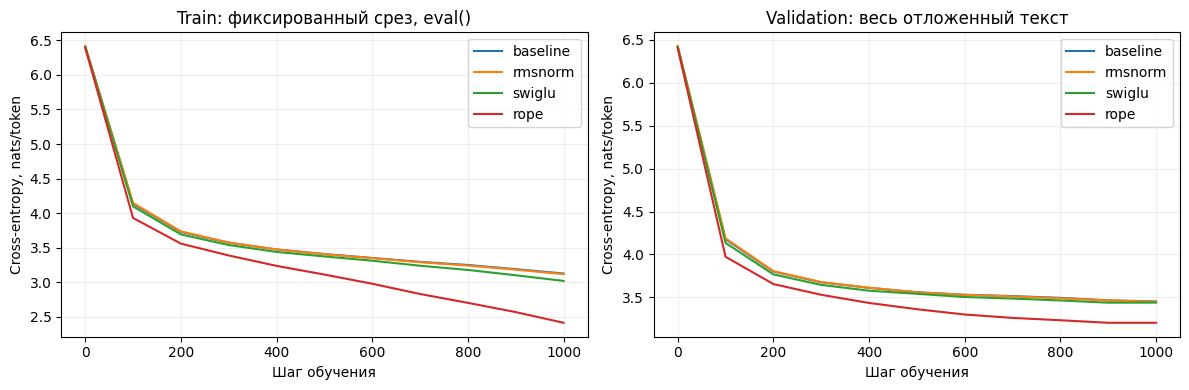

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    for axis, metric in zip(axes, ('train_loss', 'val_loss')):
        axis.plot([r['step'] for r in history], [r[metric] for r in history], label=name)

for axis, title in zip(axes, ('Train: фиксированный срез, eval()', 'Validation: весь отложенный текст')):
    axis.set(xlabel='Шаг обучения', ylabel='Cross-entropy, nats/token', title=title)
    axis.legend()
    axis.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(ARTIFACTS / 'loss_curves.png', dpi=150)
plt.show()

In [29]:
PROMPTS = ['Мой дядя самых честных правил,\n', 'Любви все возрасты покорны;\n']
samples = []
for name, _ in experiments:
    model, saved_merges, saved_vocab, checkpoint = load_checkpoint(ARTIFACTS / f'{name}.pt')
    for prompt in PROMPTS:
        for temperature in (0.0, 0.8):
            torch.manual_seed(SEED)

            prefix = torch.tensor([encode(prompt, saved_merges)], dtype=torch.long, device=DEVICE)
            generated = generate(model, prefix, max_new_tokens=80, temperature=temperature)[0].tolist()
            text = decode(generated, saved_vocab)

            print(f'\n[{name}, step={checkpoint["step"]}, T={temperature}]\n{text}')
            samples.append(
                dict(
                    model=name,
                    step=checkpoint['step'],
                    prompt=prompt,
                    temperature=temperature,
                    text=text,
                )
            )


[baseline, step=1000, T=0.0]
Мой дядя самых честных правил,
И в так, в так, в темясь,
И в так, в так, видетремя,
И в так, в темя в темя,
И в темя в темя, видя,
И в тем, видится, в темя,
И

[baseline, step=1000, T=0.8]
Мой дядя самых честных правил,
Нездеснак тем кого,
Явет с ничеселой сем,
Междителька счту послив,
Сердечтрачит сченья.



XXI

Ку грем одит проверредает
«Татьяна Татьяна?»

[baseline, step=1000, T=0.0]
Любви все возрасты покорны;
Походит, в тохноворе,
И в тошишишишь, в том спе
И встременяновью посленный
И возвался, в тенный,
И видит, в темен и в темя



[baseline, step=1000, T=0.8]
Любви все возрасты покорны;
Нездоще тем кого,
Явет с ней чуждо мы окой
Издруг! ду посливо вищут.
У старю в про домахору
И одит проверредает;
Татьяна Татьяна душ

[rmsnorm, step=1000, T=0.0]
Мой дядя самых честных правил,
И в так, в темностье в темя,
И в так, в темя в темя спе
И в темяще в темя спешье,
И в так, видится, в темя,
И в темя в темя в

[rmsnorm, step=1000, T=0.8]
Мой дядя самых честных правил,
Нездеснак тем кого,
Явет с ничеселой,
С окак ли сохного здески,
Не звете печрахазать,
Перные полно поны
Когда-будь мы,
С толного дри д



[rmsnorm, step=1000, T=0.0]
Любви все возрасты покорны;
И в тох, в тохнях в тохновь,
И в тошишишь, в тохновь,
И в тохновье в тихохновь,
И в тошишишь, в тохновь,

[rmsnorm, step=1000, T=0.8]
Любви все возрасты покорны;
Нуя, она в шуме,
Явет с ничесенывя,
Междит со счту пески,
Не звете печрах оная
Перные полно,
И одна простерредает;
Татьяна Татьяна и д

[swiglu, step=900, T=0.0]
Мой дядя самых честных правил,
И верноспремя волном спрем
И волномновьемя волном самом
И встремя волновьемя,
И волновьемя волном спрем
И волновьемя волном



[swiglu, step=900, T=0.8]
Мой дядя самых честных правил,
Нуя, онаясь не знаясь.
К ней чуждвянья,
И меня счту послива, он. Евграх
И привидно берно поным одитал,
Четушно в толновьною.

[swiglu, step=900, T=0.0]
Любви все возрасты покорны;
И верно, волня волном спрем
И волновольное волном спора
И волновьемя волновьем
И волном спремя волном спрем
И волномномновьем

[swiglu, step=900, T=0.8]
Любви все возрасты покорны;
Несь, опелестье,
Явет с ничеселыне!
Предин воседо счасторей
Никоми молодной эзы:
И дома полно, пами радостей
Чужу ним толного тем
Он



[rope, step=900, T=0.0]
Мой дядя самых честных правил,
И волненье, и в сплетний,
И вот с ним послею печальной
И встремя в томешится.
Она в томное волненье
И встремя волненье,
И волненье, спит

[rope, step=900, T=0.8]
Мой дядя самых честных правил,
Нунил он моге нее,
Я не звучал бые гранит,
И верен пончту посвил
Не тихое голраныю видит.



XXXIV

Меркажен проверредь ним толко;
Татья



[rope, step=900, T=0.0]
Любви все возрасты покорны;
И вот окно, в томном печальной
И вот с нем утреные
И волненье, и вершие моды,
И вот одное в томноме
И видие волненье,
И вот оставлен

[rope, step=900, T=0.8]
Любви все возрасты покорны;
Ну тут она темное,
Явлые тихо оне!
Пред это сохранты послыши.
«Ах! стары: про тышка,
Мои радость оредает
«Татьяна, ты, в


In [30]:
(ARTIFACTS / 'samples.json').write_text(json.dumps(samples, ensure_ascii=False, indent=2), encoding='utf-8')

4818

### 5.3. Итоговый анализ — TODO 9

Ответьте на вопросы, ссылаясь на вашу таблицу, графики и примеры.

1. Какая конфигурация дала минимальный validation loss? Каков разрыв с baseline и как изменилось число параметров? Укажите устройство, режим и фактический бюджет.
2. Что изменилось при каждом последовательном переходе? Объясните хотя бы один результат, который не совпал с вашим ожиданием; если все совпали, укажите альтернативное объяснение.
3. Есть ли признаки переобучения? Почему выбор лучшего checkpoint не превращает validation в независимый test? Что ограничивает выводы при одном seed?
4. Чем отличаются greedy и sampling в ваших примерах? Отделите повторение цитат и стилистическое сходство от способности обобщать. Приведите неудачное продолжение.
5. Почему нельзя по этим прогонам заключить, что RoPE улучшает длинный контекст, а RMSNorm обязательно ускоряет любую LLM? Какой один следующий эксперимент помог бы проверить ваше объяснение, и что вы в нём зафиксируете?
6. Назовите одну найденную ошибку и проверку, которая помогла её локализовать. Если ошибок не встретилось, объясните, какую из проверок вы считаете наиболее полезной и почему.

**Ответ.**

**Условия.** Все четыре конфигурации обучены в основном режиме с полным бюджетом, без уменьшений: d_model=192, 4 блока, 6 голов (D=32), окно max_seq_len=128, batch 32, 1000 шагов, AdamW lr=3e-4, betas (0.9; 0.95), weight decay 0.1, dropout 0.1, seed 42; byte-level BPE на 512 токенов, разбиение 9:1 **до** обучения BPE (77 219 train / 8 520 val токенов). Устройство — CPU (PyTorch 2.8.0, локальный прогон; CUDA недоступен в среде выполнения), все четыре модели обучены на одном и том же устройстве; порядок батчей одинаков благодаря отдельному `torch.Generator`, засеянному тем же SEED, поэтому прогоны строго сопоставимы. Время — 110–142 с на модель. Ноутбук готов к перезапуску в Colab: `DEVICE` сам выберет GPU, код устройства-agnostic (маска и частоты RoPE создаются на устройстве входа).

**1. Лучшая конфигурация и разрыв.** Минимальный val CE у **rope**: 3.203 (PPL 24.62) против baseline 3.452 (PPL 31.58) — разрыв −0.249 nats/токен (−7.2 % relative CE), PPL ниже на 22 %. Число параметров при этом не выросло, а уменьшилось: 1 967 808 против 1 969 536 (−1 728 — это 9 нормализаций × 192: RMSNorm не хранит bias). Значит, выигрыш создан не ёмкостью модели, а свойством компонента.

**2. Последовательные переходы.**

- **baseline → rmsnorm:** val CE 3.452 → 3.449 (−0.003), параметры −1 728. Прогноз «примерно нейтрально» совпал: на 4 слоях LN и RMS математически почти эквивалентны, и их различия (вычитание среднего, beta) на таком масштабе не успевают ни помочь, ни навредить.
- **rmsnorm → swiglu:** val CE 3.449 → 3.438 (−0.011), параметры те же (обе FFN — 8d²). Прогноз «небольшой выигрыш» совпал, но с неочевидной деталью: train CE на 1000-м шаге у swiglu 3.021 против 3.119 у rmsnorm (−0.098), то есть gated FFN заметно быстрее подгоняет train, а val улучшается лишь на 0.011 — эффект ушёл в подгонку, а не в обобщение. Отсюда же первый сигнал плато: best_step=900, к 1000-му val чуть откатывается (3.438 → 3.439).
- **swiglu → rope:** val CE 3.438 → 3.203 (−0.235) — **неожиданный результат**: я прогнозировал нейтрально (RoPE использует тот же набор частот θ_i = 10000^(−2i/D), что и синусоиды, а окно всего 128), но именно RoPE дал почти весь суммарный выигрыш, причём train CE тоже упал сильно (2.570 на 900-м шаге против 3.103 у swiglu) — значит, дело не только в обобщении. Моё объяснение: в baseline позиции примешиваются к эмбеддингам в том же векторе residual-потока, что и содержимое токена, и далее нормализуются вместе с ним — на маленьком корпусе это заставляет модель тратить ёмкость на размешивание «позиции» и «содержания»; RoPE не расходует канал residual-потока вообще, а вносит позицию напрямую в скоры внимания через относительные повороты Q/K. Для «Онегина» с его локальной структурой (анфоры «И в…», рифменные пары, повторы) относительные смещения — более точный индуктивный bias, чем абсолютные координаты. Альтернативное объяснение, которое я не могу исключить: повёрнутые Q/K формируют более «острые» распределения внимания в ранних слоях и просто ускоряют сходимость на фиксированных 1000 шагов; различить эти гипотезы можно только удлинением обучения и повторами с другими seed (см. п. 5).

**3. Переобучение и роль validation.** Классического разворота val вверх нет: у baseline и rmsnorm val монотонно падает до 1000-го шага, у swiglu и rope лучший checkpoint на 900-м, к 1000-му val стоит на месте (+0.001). Но разрыв val−train растёт у всех: 0.01 на старте → 0.32 у baseline/rmsnorm, 0.42 у swiglu, 0.79 у rope к концу — ранний признак переобучения: train продолжает падать, val уже не даёт выигрыша. Выбор лучшего checkpoint по validation **не** превращает её в независимый test, потому что мы посмотрели на неё 11 раз за прогон и взяли минимум её шума: такая «лучшая» val-оценка оптимистично смещена (при 8 520 val-токенах шум оценки — порядка сотых nats, сопоставимо с эффектами rmsnorm/swiglu). Честный test — это ещё один отложенный кусок текста, который не участвует ни в обучении, ни в выборе checkpoint. Ограничение одного seed: различия −0.003 и −0.011 почти наверняка меньше разброса между запусками; даже разрыв rope −0.235 без повторов формально остаётся единичной выборкой.

**4. Greedy vs sampling.** Greedy у всех моделей скатывается в циклы — типичная деградация argmax-декодирования слабой модели: baseline — «И в так, в так, в темясь, / И в так, в так, видетремя…», swiglu — навязчивое «волномновьемя волном самом». Sampling при T=0.8 разнообразнее и местами ближе к корпусу: rope выдаёт «И волненье, и в сплетний…» (волненье — реальное слово «Онегина»), вставляет структурные маркеры корпуса — римские номера строф (XXI, XXXIV) и реплики в кавычках («Татьяна, ты, в…»). Но это стилистическое сходство и выученный формат, а не обобщение смысла: большая часть сгенерированных слов — несуществующие последовательности байтов («Меркажен проверредь ним толко» у rope T=0.8, «Нездеснак тем кого» у baseline T=0.8 — при словаре 512 BPE-мерджей целые слова часто не помещаются в один токен, и модель собирает невалидные байтовые цепочки). Неудачное продолжение из ноутбука: baseline greedy — «Любви все возрасты покорны; / Походит, в тохноворе, / И в тошишишишь, в том спе…» — ритм, переводы строк и знак препинания скопированы верно, содержание — шум. Повторение слов промпта («дядя», «правил») и форматных маркеров — это работа локального контекста и запоминания частот, а не понимания текста.

**5. Почему выводы нельзя обобщать.** Про RoPE: во всех прогонах контекст фиксирован (128) и evaluation никогда не выходит за пределы обученного окна — «улучшение длинного контекста» в этом эксперименте просто не измерялось; измерено лишь, что при 128 позициях RoPE лучше аддитивных синусоид на этом корпусе. Про RMSNorm: мы не измеряли ни скорость инференса (секунды CPU смешивают эффект компонента с особенностями ядер), ни стабильность глубоких сетей — 4 слоя не тестируют ни то, ни другое, а −0.003 nats не даёт права утверждать что-то про «любую LLM». К этому добавляются один корпус, один seed, один бюджет шагов. Следующий эксперимент (один): переобучить пары baseline vs rope с тем же бюджетом на max_seq_len=512 с тремя разными seed, затем evaluate на валидационных окнах длины 128/256/512 (включая длины, не встречавшиеся при обучении). Зафиксирую: val CE (mean±std по seed) на каждой длине, форму кривой «val CE vs длина контекста» за границей обученного окна (экстраполяция синусоид против RoPE) и число шагов до лучшего checkpoint. Если разрыв rope растёт с длиной контекста и сохраняется при экстраполяции — гипотеза «длинноконтекстного преимущества» подтверждена; если нет — мой выигрыш на 128 позициях был эффектом сходимости, а не позиционного механизма.

**6. Ошибка и самая полезная проверка.** Реальная ошибка случилась при сборке: первый запуск ноутбука упал с IndentationError в DecoderBlock — строка `def forward(self, x):` продублировалась при слиянии готового шаблона с моей реализацией, и у метода не оказалось тела. Локализовала её мгновенно сама первая ячейка с классами: трейсбек указал точно на строку `def forward`. Из встроенных самопроверок самая полезная — сравнение с `F.scaled_dot_product_attention(is_causal=True)` вместе с тестом причинности: одна проверка ловит сразу четыре класса ошибок (масштаб 1/√D, направление маски, ось softmax, порядок объединения голов через transpose/reshape), а тест «изменение правого хвоста входа не меняет логиты левой части» проверяет отсутствие утечки будущего через весь стек (эмбеддинг + позиции + все блоки + lm_head), а не только внутри одного attention. Вторая по ценности — проверка инвариантности скалярного произведения к общему сдвигу позиций у RoPE: она поймала бы самую коварную ошибку — забытый offset.
